# Lab 17: How to run model-written code safely

**Notebook 1 of 2: meet the code interpreter with a month of coffee receipts**

## Goal

Let a model answer a question by writing Python, run that Python on OpenAI's hosted code interpreter, and read
exactly what ran. We start with forty coffee receipts. Asked for the total, the model writes a confident number
that is wrong. Given the code interpreter, it writes a few lines of Python instead, the code runs on OpenAI's side,
and the total is right. What could that code have reached if it had run on our machine? A short probe that we
write ourselves answers that, run once in a subprocess on our machine and once in the hosted
container. Notebook 2 takes the same tool to the Chinook music
shop, where the code draws a chart from the shop's database.

## What you will learn

- Why a model's total of a long list of numbers cannot be trusted, and how to check it with Python.
- How to give a model OpenAI's hosted code interpreter on the Responses API, and read the call it made: the
  container, the code and what the code printed.
- How a chart comes back from the code interpreter as an image, and how a follow-up question reuses the same
  container.
- What a subprocess on your own machine can reach, read from a probe we wrote, and why a working folder, a timeout
  and a trimmed environment do not make a sandbox (a place where code runs with no way to reach your files or the
  network).
- Why code a model wrote runs only in an isolated place (a hosted container here, a Docker container in
  notebook 2), and never in a plain process on your machine.

## Setup

The first cell is the same in every lab: it finds the repository folder, reads the model name from `models.env`, and
takes the key from `.env` without printing it (lab 00 explains it line by line).

In [1]:
from pathlib import Path
import os
from dotenv import dotenv_values

# The repository folder is the first folder, from here upwards, that holds models.env
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "models.env").exists())

# Models and prices come from models.env; a non-empty value in .env replaces one of them
settings = dotenv_values(ROOT / "models.env")
local = dotenv_values(ROOT / ".env")
settings.update({name: value for name, value in local.items() if name in settings and value})

# The key comes from the environment or .env, and is never printed
os.environ.setdefault("OPENAI_API_KEY", local.get("OPENAI_API_KEY") or "")
assert os.environ["OPENAI_API_KEY"], "Put OPENAI_API_KEY in .env at the repository folder (copy .env.example)."

MODEL = settings["MODEL_DEFAULT"]
EFFORT = settings["REASONING_EFFORT"] or None
print("model:", MODEL, "| reasoning effort:", EFFORT, "| key found: yes")

model: gpt-6-luna | reasoning effort: none | key found: yes


The second cell makes the OpenAI client and the folder this notebook writes to. A request that runs code takes
longer than a plain answer, so the client gives each request up to 120 seconds before it fails, instead of the
default ten minutes. `outputs/` is the folder for the files this notebook writes; git ignores it.

In [2]:
from openai import OpenAI, omit

client = OpenAI(timeout=120)

OUTPUTS = ROOT / "17_Code_Execution" / "outputs"
OUTPUTS.mkdir(exist_ok=True)
print("files go to:", OUTPUTS.relative_to(ROOT))

files go to: 17_Code_Execution/outputs


---

## Part A: Ask the model to add up a month of coffee receipts

A question where only an exact answer will do: what did I spend on coffee in October? Here are the forty receipts,
in dollars, one price per coffee. `PRICES` is a plain Python list.

In [3]:
PRICES = [
    3.80, 4.25, 2.95, 5.10, 3.80, 4.60, 3.35, 2.95, 4.25, 5.45,
    3.80, 3.10, 4.75, 2.95, 4.25, 3.65, 5.10, 3.80, 4.40, 2.95,
    3.80, 4.25, 5.85, 3.35, 2.95, 4.60, 3.80, 4.15, 3.10, 4.25,
    5.10, 2.95, 3.80, 4.75, 3.65, 4.25, 2.95, 5.45, 3.80, 4.30,
]
print(len(PRICES), "coffees")

40 coffees


First the answer we can trust, from our own code. `sum(PRICES)` adds the list. Computers store most decimals
slightly inexactly, so a sum of prices can come out as something like `160.34999999999997`; `round(..., 2)` rounds
it to cents.

In [4]:
TRUE_TOTAL = round(sum(PRICES), 2)
print("total by Python:", TRUE_TOTAL)

total by Python: 160.35


$160.35. Now the same question to the model, with no tools. The question is one string:

- `", ".join(...)` writes the forty prices one after another with a comma between them;
- `f"{price:.2f}"` writes each price with two decimals, as on a receipt (`3.80`, not `3.8`);
- the last line asks for the total only, so the reply is one number we can compare.

We send it on the Responses API (`client.responses.create`), the API the code interpreter belongs to. `input` is the
user's message, `reasoning` passes the effort from `models.env` (`omit`, imported with the client, sends no effort
at all when `models.env` leaves it empty), and `response.output_text` is the reply's text.
Before you run it: will the model's total match Python's?

In [5]:
QUESTION = (
    "My coffee receipts for October, in dollars:\n"
    + ", ".join(f"{price:.2f}" for price in PRICES)
    + "\nWhat did I spend on coffee in total? Answer with the total only."
)

alone = client.responses.create(
    model=MODEL,
    reasoning={"effort": EFFORT or omit},
    input=QUESTION,
)
print("the model's total:", alone.output_text)
print("Python's total:   ", f"${TRUE_TOTAL:.2f}")

the model's total: $158.60
Python's total:    $160.35


In our run the model answered $158.60, and Python says $160.35: $1.75 off. The reply gives no sign
of doubt. It looks exactly like a right answer would.

**Why it is wrong.** A model writes its reply one token at a time, each one the likely next piece of text. Nothing
in that process adds up forty numbers the way `sum` does. On a short list the likely text is often the right
total; on forty prices it is a number of about the right size. Run the cell again and the total will probably
change. In the eleven runs we made, the model's total was wrong every time, between $157.20 and $160.00.

**Checkpoint A.** Python's total is $160.35. The model's total, with no tools, is a confident dollar amount that
differs from it.

---

## Part B: Let the model write and run the code with the code interpreter

The fix is to let Python do the adding, with the model writing the Python. OpenAI's **code interpreter** is a tool
of the Responses API that does this: the model writes Python, the API runs it in a **container** on OpenAI's side
(a small, isolated machine made for this job), and the response brings back the code and what it printed. The
model calls it "the python tool", so our question ends with *Use the python tool*.

The tool is one dictionary in `tools=[...]`:

- `"type": "code_interpreter"` names the tool;
- `"container"` says where the code runs. `"type": "auto"` asks the API to start a container for us;
  `"memory_limit": "1g"` picks the smallest size, 1 GB of memory; `"network_policy": {"type": "disabled"}` gives the
  container no internet. That is the default; we write it out so we can see it.

One more argument: `include=["code_interpreter_call.outputs"]` asks the API to send back what the code printed.
Without it, the response has the code but not its output.

⚠️ **This cell costs money:** each container is billed per session (`PRICE_CONTAINER_SESSION_USD` in `models.env`,
up to $0.03 for 1 GB), on top of the tokens.

In [6]:
CODE_INTERPRETER = {
    "type": "code_interpreter",
    "container": {"type": "auto", "memory_limit": "1g", "network_policy": {"type": "disabled"}},
}

coffee = client.responses.create(
    model=MODEL,
    reasoning={"effort": EFFORT or omit},
    input=QUESTION + " Use the python tool.",
    tools=[CODE_INTERPRETER],
    include=["code_interpreter_call.outputs"],
)
print([item.type for item in coffee.output])
print("reply:", coffee.output_text)

['code_interpreter_call', 'message']
reply: $160.35


The response's `output` is a list of items, in the order they happened: `code_interpreter_call`, then `message`. The model's reply is
`$160.35`, the same as Python's total.

The `code_interpreter_call` item is the record of the code that ran. `next(...)` walks the list and returns the
first item whose `type` is `code_interpreter_call`. The fields we read:

| Field | What is in it |
|---|---|
| `container_id` | the container the code ran in, started for this request |
| `status` | `completed` when the code finished |
| `code` | the Python the model wrote, exactly as it ran |
| `outputs` | what the code produced: a `logs` entry has the printed text, an `image` entry a picture |

In [7]:
call = next(item for item in coffee.output if item.type == "code_interpreter_call")
print("container:", call.container_id[:20] + "...")
print("status:", call.status)
print("--- the code the model wrote ---")
print(call.code)
print("--- what the code printed ---")
for output in call.outputs:
    if output.type == "logs":
        print(output.logs)

container: cntr_6af588768c64819...
status: completed
--- the code the model wrote ---
vals = [3.80, 4.25, 2.95, 5.10, 3.80, 4.60, 3.35, 2.95, 4.25, 5.45, 3.80, 3.10, 4.75, 2.95, 4.25, 3.65, 5.10, 3.80, 4.40, 2.95, 3.80, 4.25, 5.85, 3.35, 2.95, 4.60, 3.80, 4.15, 3.10, 4.25, 5.10, 2.95, 3.80, 4.75, 3.65, 4.25, 2.95, 5.45, 3.80, 4.30]
sum(vals)

--- what the code printed ---
160.35


The model's code is two lines. The first types the forty prices into a list called `vals`; the second, `sum(vals)`, adds them. The container runs code the way a notebook cell runs, so the value of the last line is printed without a `print`. The code printed `160.35`, and the model's reply repeats it.

So the arithmetic was done by Python, in the container, and the model's part was to write the code. That is a job
it does well: copying numbers from the question into a list and calling `sum` is text, not arithmetic.

**What this does not prove.** A right total shows that this code was right this time, not that the code
interpreter's answers are always right. To trust a result from the code interpreter, do what you would for any
program: read `call.code`. Notice also where the forty prices in the code came from: the model copied them from
our question. Here every copy is exact (check a few against `PRICES` by eye); notebook 2 checks a copy like this
one in code, against a database.

**Checkpoint B.** Two items, `code_interpreter_call` then `message`; code that lists the forty prices and adds them;
printed output and a reply of 160.35.

---

## Part C: Get a chart back from the same container

The code interpreter can also draw. We ask a follow-up question with `previous_response_id`, so the API continues
the conversation of Part B. The documentation says what happens to the container in auto mode: the API "creates a
new container, or reuses an active container that was used by a previous `code_interpreter_call` item in the
model's context". Part B's call is in that context, so this request should run in the same container, and both
requests share one container session.

We ask the model to show the chart with `plt.show()`. A chart that is shown comes back in `outputs` as an image; a
chart that is only saved to a file stays inside the container.

Before you run it: will the container id match Part B's?

In [8]:
chart = client.responses.create(
    model=MODEL,
    reasoning={"effort": EFFORT or omit},
    previous_response_id=coffee.id,
    input="Now draw a bar chart of the forty coffees in order, with a line at the average price. Show it with plt.show().",
    tools=[CODE_INTERPRETER],
    include=["code_interpreter_call.outputs"],
)
chart_calls = [item for item in chart.output if item.type == "code_interpreter_call"]
print("code_interpreter_call items:", len(chart_calls))
print("same container as Part B:", all(c.container_id == call.container_id for c in chart_calls))
for c in chart_calls:
    print("outputs:", [output.type for output in c.outputs])

code_interpreter_call items: 1
same container as Part B: True
outputs: ['image']


In our run the chart took one `code_interpreter_call`, and its only output is an `image`. The container id is the same as Part B's (`True`), so the two requests ran in one container.

The chart is the `image` output. Its `url` is a **data URL**: the text `data:image/png;base64,` followed by the PNG
file written as base64 text (a way to carry the bytes of a file inside a string). To get the picture back:

1. `split(",", 1)[1]` keeps the part after the first comma, the base64 text;
2. `base64.b64decode` turns that text back into the PNG's bytes;
3. `write_bytes` saves them to `outputs/coffee_chart.png`, and `Image(data=...)` shows them here.

data:image/png;base64,iVBORw0KGgoAAAANSU...


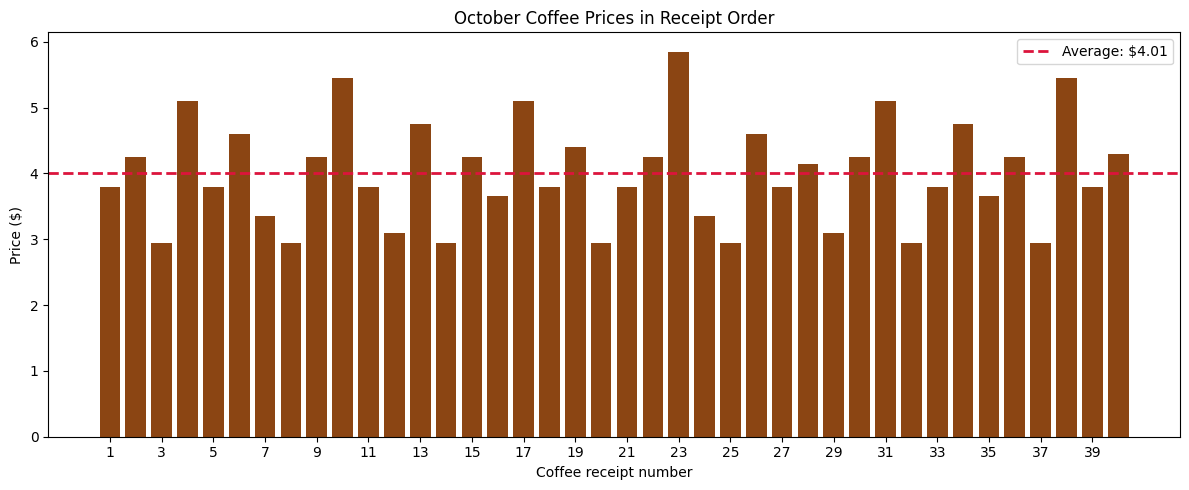

In [9]:
import base64
from IPython.display import Image, display

image = next(output for c in chart_calls for output in c.outputs if output.type == "image")
print(image.url[:40] + "...")

png = base64.b64decode(image.url.split(",", 1)[1])
(OUTPUTS / "coffee_chart.png").write_bytes(png)
display(Image(data=png, width=700))

Forty bars, one per coffee, and a line at the average price, about $4.01 ($160.35 divided by 40). The chart was
drawn by matplotlib on OpenAI's machine; what reached our notebook is the picture.

**Checkpoint C.** One or more `code_interpreter_call` items in the same container as Part B (`True`), an `image`
output, and a bar chart of the forty prices saved as `outputs/coffee_chart.png`.

---

## Part D: Test what code could reach on your machine, with a probe

The model's code ran on OpenAI's machine. What if it had run on ours?

This code was harmless, but nobody read it before it ran. The model wrote it from the text we sent, and text can
come from anywhere: a question, a file, a web page. Code that runs on your machine runs with your permissions. It
can open your files, including `.env`, which contains your API key, and send them anywhere.

We will not run model-written code here to find out what it could reach. We write a **probe** instead: a few lines
of our own that ask what any code could ask, and print only the answers.

⚠️ **The probe is fixed text, written in this notebook.** It checks whether `.env` exists; it never opens the file
or prints anything from it. No code a model wrote runs on your machine in this notebook.

Each line of the probe asks one question:

1. **`working folder:`** the name of the folder the code starts in (`Path.cwd()`; `.name` keeps only the last part
   of the path).
2. **`two folders up:`** where `../..` leads. `.resolve()` turns the relative path into a real one, and `.name` is
   that folder's name, or empty at the top of the disk, which we print as `/`.
3. **`.env there:`** whether a file called `.env` exists two folders up.
4. **`key in environment:`** whether the variable `OPENAI_API_KEY` reached the code.
5. **`network:`** whether a connection to `pypi.org` on port 443 (the HTTPS port) opens within 3 seconds.
   `socket.create_connection` raises an `OSError` when it cannot connect; we print the error's type.

In [10]:
PROBE = """import os, pathlib, socket
print("working folder:", pathlib.Path.cwd().name)
print("two folders up:", pathlib.Path("../..").resolve().name or "/")
print(".env there:", pathlib.Path("../../.env").exists())
print("key in environment:", "OPENAI_API_KEY" in os.environ)
try:
    socket.create_connection(("pypi.org", 443), timeout=3).close()
    print("network: reachable")
except OSError as error:
    print("network: blocked,", type(error).__name__)
"""
(OUTPUTS / "probe.py").write_text(PROBE)
print("probe saved as", (OUTPUTS / "probe.py").relative_to(ROOT))

probe saved as 17_Code_Execution/outputs/probe.py


First, what this notebook itself can reach. It is our own code, so it may reach everything: `.env` is in the repository
folder, and the setup cell put the key in this process's environment.

In [11]:
print(".env in the repository folder:", (ROOT / ".env").exists())
print("key in this notebook's environment:", "OPENAI_API_KEY" in os.environ)

.env in the repository folder: True
key in this notebook's environment: True


Both `True`. Now the probe in a **subprocess**, a separate program that our notebook starts. This is the first idea
most people have for running code they do not trust, with three controls that sound safe. `subprocess.run` starts
the program and waits for it:

- `[sys.executable, "probe.py"]` is the program: the same Python this notebook runs on, with our probe file;
- `cwd=OUTPUTS` is the first control, a **working folder**: the process starts in `17_Code_Execution/outputs/`;
- `env={"PATH": ...}` is the second, a **trimmed environment**: the process gets only the `PATH` variable, so the API
  key in our environment is not passed on;
- `timeout=10` is the third, a **timeout**: Python stops the process after 10 seconds;
- `capture_output=True, text=True` collects what the process prints, as text, in `result.stdout`.

Before you run it: which of the five lines will these controls change?

In [12]:
import subprocess
import sys

result = subprocess.run(
    [sys.executable, "probe.py"],
    cwd=OUTPUTS,
    env={"PATH": os.environ["PATH"]},
    timeout=10,
    capture_output=True, text=True,
)
print(result.stdout)

working folder: outputs
two folders up: ai_agents_course
.env there: True
key in environment: False
network: reachable



Read it line by line:

- **working folder: outputs**: the working folder control did its job.
- **two folders up: ai_agents_course**: from `outputs/`, `../..` is the repository folder. A working folder is where
  relative paths *start*; `..` climbs out of it.
- **.env there: True**: the file with the key is right there. Reading it would take one more line of code.
- **key in environment: False**: the trimmed environment did its job, and it did not matter, because the same key is
  in a file the process can open.
- **network: reachable**: nothing stops the process from sending what it read to any address.

A **sandbox** is a place where code runs with no way to reach your files or the network. **A working folder, a
timeout and a trimmed environment do not make one.** They set where relative paths start, how long code may run
and which variables it gets. They do not limit what it can read or where it can send it.

### The same probe in the hosted container

The code interpreter runs code that the model writes; there is no request that runs our code directly. So we ask
the model to run the probe exactly as written, and then we check that it did: `probe_call.code == PROBE` compares the
code that ran with the text we sent. Two settings make the request do only that:

- `instructions` tells the model its one job: run the user's code unchanged, once;
- `tool_choice="required"` makes the model call a tool instead of answering in words.

The model can still change a line while it copies the probe. If `the code that ran is our probe` prints `False`,
that happened, and the lines below are the answers of *its* code, not ours: print
`probe_call.code` beside `PROBE`, find the difference, and run the cell again.

⚠️ **This cell costs money:** a new request with no `previous_response_id` starts a new container session.

In [13]:
RUN_AS_WRITTEN = ("Run the user's Python code with the python tool exactly as written, once, without changing it. "
                  "Then reply with what it printed.")

probe_response = client.responses.create(
    model=MODEL,
    reasoning={"effort": EFFORT or omit},
    instructions=RUN_AS_WRITTEN,
    input=PROBE,
    tools=[CODE_INTERPRETER],
    tool_choice="required",
    include=["code_interpreter_call.outputs"],
)
probe_call = next(item for item in probe_response.output if item.type == "code_interpreter_call")
print("the code that ran is our probe:", probe_call.code == PROBE)
for output in probe_call.outputs:
    if output.type == "logs":
        print(output.logs)

the code that ran is our probe: True
working folder: oai
two folders up: /
.env there: False
key in environment: False
network: blocked, gaierror



The code that ran is our probe (`True`), and it printed:

- **working folder: oai**: a folder on OpenAI's machine.
- **two folders up: /**: the top of that machine's disk. There is no repository to climb to.
- **.env there: False** and **key in environment: False**: our `.env` file and our key are on another computer.
  The key we used to call the API never reaches the container.
- **network: blocked, gaierror**: `gaierror` means the name `pypi.org` could not even be looked up. That is the
  `network_policy` we set.

The same five lines in the two places:

| Where the probe ran | `.env there` | `key in environment` | `network` |
|---|---|---|---|
| a subprocess on our machine, with a working folder, a timeout and a trimmed environment | True | False | reachable |
| the hosted code interpreter's container, on OpenAI's machine | False | False | blocked |

**Lesson to Remember.** Where code runs sets what it can reach. Code a model wrote runs only where it cannot reach
your files or the network: a hosted container like this one, or a container on your own machine with no
network and one mounted folder (notebook 2 has an optional part for readers with Docker). A plain subprocess is never
that place, however many controls it has: as the probe showed, it still finds `.env` and the network.

**Checkpoint D.** From the subprocess: `.env there: True`, `key in environment: False`, `network: reachable`. From
the hosted container: the code that ran is our probe (`True`), `working folder: oai`, `.env there: False`,
`key in environment: False`, `network: blocked, gaierror`.

---

## What you can do now

- Check a model's arithmetic against Python, and say why a long sum is a job for code (Part A).
- Give a model the hosted code interpreter on the Responses API, and read its `code_interpreter_call`: the
  container, the code and the printed output (Part B).
- Get a chart back as an image output, decode it, and keep a follow-up in the same container with
  `previous_response_id` (Part C).
- Test a place where code runs with a probe of your own, and say why a working folder, a timeout and a trimmed
  environment do not make a sandbox (Part D).
- Say where code a model wrote may run: a hosted container or an isolated container on your machine, never a plain
  process (Part D).

## Troubleshooting

| What you see | Why | Fix |
|---|---|---|
| `StopIteration` on the line `call = next(...)` | the response has no `code_interpreter_call` item: the model answered in words without running code | print `[item.type for item in coffee.output]`; keep *Use the python tool* in the question, or add `tool_choice="required"` |
| `TypeError: 'NoneType' object is not iterable` on `for output in call.outputs` | the request had no `include=["code_interpreter_call.outputs"]`, so `outputs` is `None` | add the `include` argument and run the cell again |
| `same container as Part B: False` | more than 20 minutes passed since Part B and its container expired, so the API started a new one | expected after a break; it costs one more session |
| `the code that ran is our probe: False` | the model changed something while copying the probe, so the lines below answer its code, not ours | print `probe_call.code` beside `PROBE`, read the difference, and run the cell again |
| the subprocess prints `.env there: False` | your key is in an environment variable, not in a `.env` file in the repository folder | nothing to fix; the other lines still show what a subprocess reaches |

## Challenge

1. **Roll two dice 10,000 times.** Ask the model, with the code interpreter: *Roll two six-sided dice 10,000 times
   and count how often the total is 7. Use the python tool.* Print the code it ran and what it printed. Then, in the
   same container (`previous_response_id`), ask for a bar chart of how often each total from 2 to 12 came up, and
   save the image. *Expected:* code that uses Python's `random` module, a count of sevens near 10,000 / 6 ≈ 1,667
   (it changes with every run), the same container id for both requests, and a chart with its highest bar at 7.
2. **Find out which user the code runs as in the hosted container.** Add a line to a copy of `PROBE` that prints the user the code runs
   as (`import getpass` and `getpass.getuser()`), run it **in the hosted container only**, as in Part D, and check
   that the code that ran is your text. *Expected:* `True` for the comparison, and a user name that is not yours.

A worked solution, run with its outputs, is in `solved/17a_meet_code_execution_solution.ipynb`.

## Going further

**What a run costs.** A call to the code interpreter has two prices: the tokens, as for any call, and the container
session, which `models.env` prices per session. The cell below adds them up for the requests in this notebook. The
number of sessions is the number of different containers the calls ran in.

In [14]:
PRICE_IN = float(settings["PRICE_INPUT_PER_MILLION"]) / 1_000_000
PRICE_OUT = float(settings["PRICE_OUTPUT_PER_MILLION"]) / 1_000_000
SESSION = float(settings["PRICE_CONTAINER_SESSION_USD"])

requests = [coffee, chart, probe_response]
tokens_usd = sum(r.usage.input_tokens * PRICE_IN + r.usage.output_tokens * PRICE_OUT for r in requests)
containers = {item.container_id for r in requests for item in r.output if item.type == "code_interpreter_call"}
print("input tokens:", [r.usage.input_tokens for r in requests])
print(f"tokens ${tokens_usd:.5f} + {len(containers)} sessions x ${SESSION:.2f} = ${tokens_usd + len(containers) * SESSION:.4f}")

input tokens: [1672, 2782, 1515]
tokens $0.00096 + 2 sessions x $0.03 = $0.0610


In our run the three requests sent 1,672, 2,782 and 1,515 input tokens, $0.00096 in all with their output tokens, and ran in two containers: Parts B and C shared one, and Part D started its own. So the notebook cost at most $0.061, and $0.06 of that is the two sessions. The tool adds its own instructions to every request, which is why even the short probe request
sends about 1,500 input tokens. The sessions are most of the bill, so reusing a container with
`previous_response_id` (Part C) is the cheap way to ask a follow-up. OpenAI's pricing page lists the 1 GB
container at $0.03 per 20-minute session, and says eligible sessions are "billed by the minute, with a 5-minute
minimum per session". Our sum counts every session at the full $0.03, so it is the most these requests can cost;
a session billed by the minute costs less.

**Other places code can run.** The code interpreter is one hosted option. Others give an agent the same kind of
isolated machine: E2B, Modal, Daytona and Azure Container Apps dynamic sessions. On your own machine the isolated
place is a container with no network and one mounted folder: notebook 2's optional Part E builds one with Docker.

## Resources

- [OpenAI: code interpreter](https://developers.openai.com/api/docs/guides/tools-code-interpreter): the tool, auto
  containers and their reuse, memory sizes, the 20-minute expiry, and the files a container creates
- [OpenAI: pricing, built-in tools](https://developers.openai.com/api/docs/pricing): the container session prices
- [Python: `subprocess`](https://docs.python.org/3/library/subprocess.html): `run`, `cwd`, `env`, `timeout` and
  `capture_output`
- [Python: `base64`](https://docs.python.org/3/library/base64.html): `b64decode`

Next: [notebook 2](17b_code_execution_at_the_desk.ipynb), the code interpreter at the Chinook desk.